# Movie Ratings Project 2

**Question:** How does the user movie network change when we retain only the high rated relationships, and what can we infer about users and movies?

In [3]:
from pathlib import Path
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
USER_COLOR = '#2563EB'
MOVIE_COLOR = '#E58332'
SEED = 42

### Load Data
In this I chose to use some movie ratings data that I uploaded to github for replicability.




In [4]:
RATINGS_URL = 'https://raw.githubusercontent.com/lher96/DATA612/main/ratings.csv'
ratings_path = Path('ratings.csv')
raw = pd.read_csv(ratings_path if ratings_path.exists() else RATINGS_URL)
display(raw.head())
print(f'Original rows: {len(raw):,}')
print('Columns:', ', '.join(raw.columns))

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


Original rows: 100,836
Columns: userId, movieId, rating, timestamp


# Clean and Check
We check missing values and rating bounds before building the graph and check for multiple rows. This makes one edge correspond to one user's latest available rating of one movie.

In [5]:
required = ['userId', 'movieId', 'rating', 'timestamp']
assert set(required).issubset(raw.columns), 'Required columns are missing.'
ratings = raw.dropna(subset=required).copy()
ratings = ratings[ratings['rating'].between(0.5, 5)].copy()
for column in ['userId', 'movieId']:
    assert (ratings[column] % 1 == 0).all(), f'{column} must contain integer IDs.'
    ratings[column] = ratings[column].astype(int)
duplicate_pairs = ratings.duplicated(['userId', 'movieId']).sum()
ratings = (ratings.sort_values('timestamp')
           .drop_duplicates(['userId', 'movieId'], keep='last'))
display(pd.Series({
    'Original rows': len(raw),
    'Final edges': len(ratings),
    'Unique users': ratings.userId.nunique(),
    'Unique movies': ratings.movieId.nunique()
}, name='Count').to_frame())

,Count
Original rows,100836
Final edges,100836
Unique users,610
Unique movies,9724


In [4]:
G = nx.Graph()
G.add_nodes_from((f'user_{u}', {'bipartite': 0, 'node_type': 'user'})
                 for u in ratings.userId.unique())
G.add_nodes_from((f'movie_{m}', {'bipartite': 1, 'node_type': 'movie'})
                 for m in ratings.movieId.unique())
G.add_weighted_edges_from((f'user_{u}', f'movie_{m}', float(r))
                          for u, m, r in ratings[['userId', 'movieId', 'rating']].itertuples(index=False, name=None))
assert nx.is_bipartite(G)
assert all(G.nodes[u]['bipartite'] != G.nodes[v]['bipartite'] for u, v in G.edges)
assert G.number_of_edges() == len(ratings)
print(f'{G.number_of_nodes():,} nodes and {G.number_of_edges():,} edges')
print('Verified: every edge joins a user to a movie.')

10,334 nodes and 100,836 edges
Verified: every edge joins a user to a movie.


# Inspect the rating weights

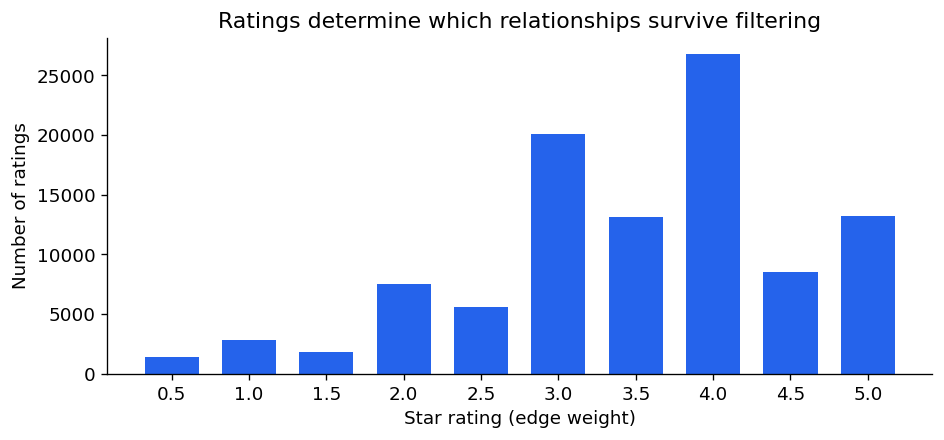

In [5]:
counts = ratings.rating.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(counts.index, counts.values, width=0.35, color=USER_COLOR)
ax.set(xlabel='Star rating (edge weight)', ylabel='Number of ratings',
       title='Ratings determine which relationships survive filtering')
ax.set_xticks(counts.index)
plt.tight_layout()
plt.show()

#Apply the island method


In [6]:
thresholds = [0.5, 3.5, 4.0, 4.5, 5.0]
graphs = {}
summary_rows = []
for threshold in thresholds:
    H = G.edge_subgraph([(u, v) for u, v, d in G.edges(data=True)
                         if d['weight'] >= threshold]).copy()
    graphs[threshold] = H
    components = list(nx.connected_components(H))
    n_users = sum(d['bipartite'] == 0 for _, d in H.nodes(data=True))
    n_movies = H.number_of_nodes() - n_users
    largest_size = max(map(len, components), default=0)
    summary_rows.append({
        'Minimum rating': threshold, 'Users': n_users, 'Movies': n_movies,
        'Edges': H.number_of_edges(),
        'Edges retained (%)': 100 * H.number_of_edges() / G.number_of_edges(),
        'Nodes removed': G.number_of_nodes() - H.number_of_nodes(),
        'Components': len(components), 'Largest component nodes': largest_size,
        'Largest component (%)': 100 * largest_size / max(1, H.number_of_nodes()),
        'Bipartite density': H.number_of_edges() / max(1, n_users * n_movies)
    })
summary = pd.DataFrame(summary_rows)
display(summary.round(4))

,Minimum rating,Users,Movies,Edges,Edges retained (%),Nodes removed,Components,Largest component nodes,Largest component (%),Bipartite density
0,0.5,610,9724,100836,100.0000,0,1,10334,100.0000,0.0170
1,3.5,609,7363,61716,61.2043,2362,1,7972,100.0000,0.0138
2,4.0,609,6298,48580,48.1772,3427,1,6907,100.0000,0.0127
3,4.5,598,4056,21762,21.5816,5680,1,4654,100.0000,0.0090
4,5.0,573,2954,13211,13.1015,6807,6,3517,99.7165,0.0078


As the minimum rating increases, the network becomes smaller and less dense, with 13.1% of the original connections at five stars. Then we see 99.7% of the users and movies left still belong to one large connected component despite the network splitting. This suggests that the shared highly rated movies still stay connected even when we actually remove many.

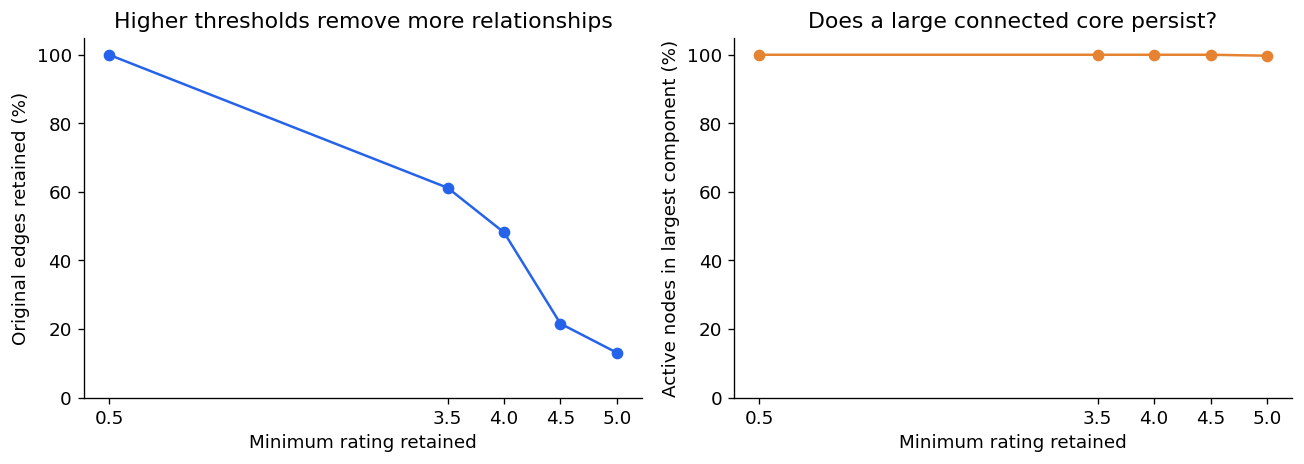

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(summary['Minimum rating'], summary['Edges retained (%)'], marker='o', color=USER_COLOR)
axes[0].set(title='Higher thresholds remove more relationships',
            xlabel='Minimum rating retained', ylabel='Original edges retained (%)', ylim=(0, 105))
axes[1].plot(summary['Minimum rating'], summary['Largest component (%)'], marker='o', color=MOVIE_COLOR)
axes[1].set(title='Does a large connected core persist?',
            xlabel='Minimum rating retained', ylabel='Active nodes in largest component (%)', ylim=(0, 105))
for ax in axes:
    ax.set_xticks(thresholds)
plt.tight_layout()
plt.show()

#Choose a reduced network and examine its components
We use 5 stars to focus on the strongest expressed approval. This choice answers a substantive question rather than guaranteeing visually separate islands.

In [8]:
SELECTED_THRESHOLD = 5.0
H = graphs[SELECTED_THRESHOLD]
components = sorted(nx.connected_components(H), key=len, reverse=True)
component_rows = []
for rank, members in enumerate(components, start=1):
    sub = H.subgraph(members)
    users_n = sum(H.nodes[n]['bipartite'] == 0 for n in members)
    component_rows.append({'Component': rank, 'Nodes': len(members),
                           'Users': users_n, 'Movies': len(members) - users_n,
                           'Edges': sub.number_of_edges()})
component_table = pd.DataFrame(component_rows)
display(component_table.head(10))
print(f'Total components at {SELECTED_THRESHOLD:g} stars: {len(components):,}')

,Component,Nodes,Users,Movies,Edges
0,1,3517,568,2949,13206
1,2,2,1,1,1
2,3,2,1,1,1
3,4,2,1,1,1
4,5,2,1,1,1
5,6,2,1,1,1


Total components at 5 stars: 6


In [9]:
qualified = ratings[ratings.rating >= SELECTED_THRESHOLD]
user_stats = ratings.groupby('userId').agg(
    movies_rated=('movieId', 'nunique'), mean_rating=('rating', 'mean'))
user_stats['high_rating_movies'] = qualified.groupby('userId').movieId.nunique().reindex(user_stats.index, fill_value=0)
user_stats['high_rating_share'] = user_stats.high_rating_movies / user_stats.movies_rated
movie_stats = ratings.groupby('movieId').agg(
    raters=('userId', 'nunique'), mean_rating=('rating', 'mean'))
movie_stats['high_rating_users'] = qualified.groupby('movieId').userId.nunique().reindex(movie_stats.index, fill_value=0)
movie_stats['high_rating_share'] = movie_stats.high_rating_users / movie_stats.raters
top_users = user_stats.sort_values(['high_rating_movies', 'movies_rated'], ascending=False).head(10)
top_movies = movie_stats.sort_values(['high_rating_users', 'raters'], ascending=False).head(10)
print('Users with the most qualifying movie ratings')
display(top_users.round(3))
print('Movies with the most qualifying users (IDs, not titles)')
display(top_movies.round(3))
print('Movies with the highest qualifying share among those with at least 50 ratings')
display(movie_stats[movie_stats.raters >= 50].sort_values(
    ['high_rating_share', 'raters'], ascending=False).head(10).round(3))

Users with the most qualifying movie ratings


,movies_rated,mean_rating,high_rating_movies,high_rating_share
userId,,,,
380,1218,3.673,274,0.225
414,2698,3.392,248,0.092
275,403,4.087,189,0.469
305,677,3.925,182,0.269
610,1302,3.689,180,0.138
603,943,3.508,170,0.180
597,443,3.977,169,0.381
105,722,4.116,135,0.187
122,292,4.546,124,0.425


Movies with the most qualifying users (IDs, not titles)


,raters,mean_rating,high_rating_users,high_rating_share
movieId,,,,
318,317,4.429,153,0.483
296,307,4.197,123,0.401
356,329,4.164,116,0.353
2571,278,4.192,109,0.392
260,251,4.231,104,0.414
593,279,4.161,92,0.330
527,220,4.225,92,0.418
858,192,4.289,88,0.458
2959,218,4.273,81,0.372


Movies with the highest qualifying share among those with at least 50 ratings


,raters,mean_rating,high_rating_users,high_rating_share
movieId,,,,
318,317,4.429,153,0.483
858,192,4.289,88,0.458
1208,107,4.220,45,0.421
527,220,4.225,92,0.418
260,251,4.231,104,0.414
912,100,4.240,41,0.410
296,307,4.197,123,0.401
2324,88,4.148,35,0.398
2571,278,4.192,109,0.392


The 50 rating minimum in the final table is due to the potential of many movies that may have few ratings. This was a weakness in this dataset when I previously used something similar for predictive modeling.

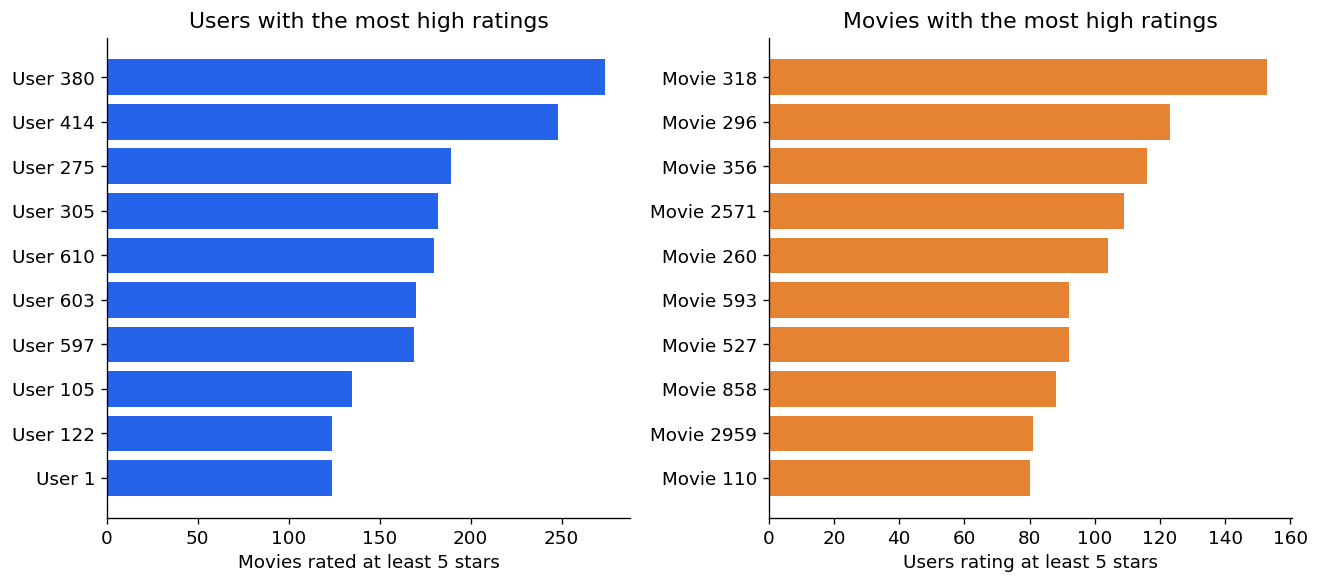

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].barh([f'User {i}' for i in top_users.index][::-1], top_users.high_rating_movies.values[::-1], color=USER_COLOR)
axes[0].set(title='Users with the most high ratings', xlabel=f'Movies rated at least {SELECTED_THRESHOLD:g} stars')
axes[1].barh([f'Movie {i}' for i in top_movies.index][::-1], top_movies.high_rating_users.values[::-1], color=MOVIE_COLOR)
axes[1].set(title='Movies with the most high ratings', xlabel=f'Users rating at least {SELECTED_THRESHOLD:g} stars')
plt.tight_layout()
plt.show()

#Visualize a clearly defined subset
Here we have the five movies with the most ratings then the first 35 qualifying users sorted by ID for each movie. We include all qualifyied edges for those users and movies we chose.

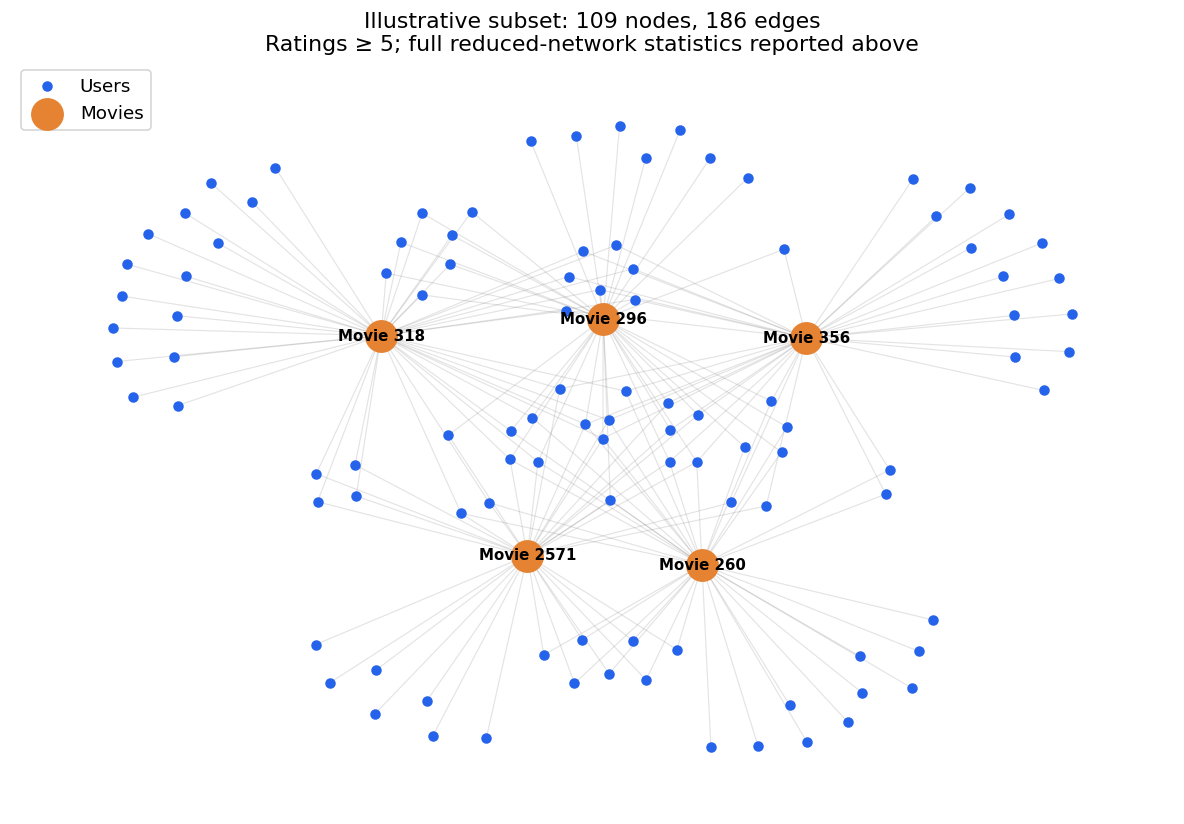

In [11]:
display_movie_ids = list(top_movies.index[:5])
display_users = set()
for movie_id in display_movie_ids:
    eligible = qualified.loc[qualified.movieId == movie_id, 'userId'].sort_values().head(35)
    display_users.update(f'user_{u}' for u in eligible)
display_movies = {f'movie_{m}' for m in display_movie_ids}
V = H.subgraph(display_users | display_movies).copy()
pos = nx.spring_layout(V, seed=SEED, iterations=100, weight=None)
fig, ax = plt.subplots(figsize=(10, 7))
nx.draw_networkx_edges(V, pos, ax=ax, alpha=0.20, edge_color='#777777', width=0.7)
nx.draw_networkx_nodes(V, pos, nodelist=sorted(display_users & set(V)),
                       node_color=USER_COLOR, node_size=28, label='Users', ax=ax)
nx.draw_networkx_nodes(V, pos, nodelist=sorted(display_movies & set(V)),
                       node_color=MOVIE_COLOR, node_size=350, label='Movies', ax=ax)
nx.draw_networkx_labels(V, pos, labels={n: n.replace('movie_', 'Movie ') for n in display_movies & set(V)},
                       font_size=9, font_weight='bold', ax=ax)
ax.set_title(f'Illustrative subset: {V.number_of_nodes()} nodes, {V.number_of_edges()} edges\nRatings ≥ {SELECTED_THRESHOLD:g}; full reduced-network statistics reported above')
ax.legend(loc='upper left')
ax.axis('off')
plt.tight_layout()
plt.show()

 #Dataset and construction.
- I analyzed 100,836 ratings linking 610 users and 9,724 movies. The network is bipartite because every edge connects a user to a movie. Star ratings serve as edge weights, representing the strength of expressed approval.

- I applied the island method by retaining ratings greater than or equal to 5 stars and removing nodes with no remaining connections. This showed 13,211 edges, 573 users, and 2,954 movies and the reduced graph contains 6 connected components.
- Something interesting was User 380 who had the most qualifying movie connections with 274 qualifying ratings out of 1,218 total movie ratings. This reflects more upon this users ratings than any influence on our results
- Movie 318 had the most user connections with having ratings from 153 distinct users.
## Interpretation.
- Removed edges represent real interactions, and removed nodes may simply lack ratings above the chosen threshold. The reduced graph shows strong approval relationships within this dataset but it certainly does not establish causal influence, universal movie quality, or demographic differences. It could be interesting to repeat this type of data for different countries and add a categorical variable of genre to see what differences exist.